# Homework 8 — The repressilator: simulation, stability diagram, and why it oscillates

**Module 1 — deterministic** · Hao-Tian Jin · 2026-11-09
*based on Elowitz & Leibler, Nature 403, 335–338 (2000)*

**Summary.** Three repressors wired in a cycle (LacI ⊣ TetR ⊣ cI ⊣ LacI) make an *odd*
negative-feedback loop. At the paper's parameter set the six-ODE model has a unique steady
state whose Jacobian has a complex pair with **positive real part**: the state is a hyperbolic
saddle, so generic trajectories are repelled and approach a limit cycle (§3 gives the precise,
global argument).

| quantity | value | how obtained |
|---|---|---|
| steady-state protein $p^*$ | 3.42 $K_M$ | $p=\alpha/(1+p^n)+\alpha_0$ |
| unstable eigenvalue | $+0.035\pm0.248\,i$ | linearization |
| period | 105 min ($36.4$ mRNA lifetimes) | simulation |
| Hopf frequency (linear) | period 69 min | $\nu=\beta X\sqrt3/[2(1+\beta)]$ |

The phase diagram (paper Fig. 1b) is reproduced from the Hopf boundary. The same analysis
explains which circuits do **not** oscillate: a single self-repressing gene and rings with an
even number of repressors converge to a stable steady state (the two-repressor ring is
bistable).

## Model

Six variables, the mRNA $m_i$ and protein $p_i$ of each repressor
$i\in\{\mathrm{lacI},\mathrm{tetR},\mathrm{cI}\}$:

$$
\frac{dm_i}{dt}=-m_i+\frac{\alpha}{1+p_j^{\,n}}+\alpha_0,
\qquad
\frac{dp_i}{dt}=\beta\,(m_i-p_i),
$$

where $p_j$ is the protein that represses gene $i$. The cycle lacI ⊣ tetR ⊣ cI ⊣ lacI means
$p_{\mathrm{lacI}}$ represses $m_{\mathrm{tetR}}$, $p_{\mathrm{tetR}}$ represses $m_{\mathrm{cI}}$,
and $p_{\mathrm{cI}}$ represses $m_{\mathrm{lacI}}$.

Time is measured in mRNA lifetimes; protein concentration in units of $K_M$, the repressor level
that half-maximally represses a promoter.

| symbol | value | meaning |
|---|---|---|
| $\alpha$ | 43 | proteins per cell at full induction, in $K_M$ (promoter strength × translation × mRNA lifetime) |
| $\alpha_0$ | 0.043 | leak; $\alpha_0/\alpha=10^{-3}$ |
| $n$ | 2 | Hill coefficient of repression |
| $\beta$ | 0.2 | protein decay rate / mRNA decay rate |
| mRNA lifetime | $2/\ln 2=2.89$ min | mRNA half-life 2 min |

These are the values behind the paper's Fig. 1c; the design point is the "X" in Fig. 1b.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import brentq
from scipy.signal import find_peaks

plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "legend.frameon": False,
})

ALPHA = 43.0        # max proteins per cell / K_M
ALPHA_0 = 0.043     # leakiness
BETA = 0.2          # protein decay / mRNA decay
N_HILL = 2.0        # repression cooperativity
MRNA_LIFETIME_MIN = 2.0 / np.log(2)   # mRNA half-life = 2 min

# state = [m_lacI, m_tetR, m_cI, p_lacI, p_tetR, p_cI]
# REPRESSOR_INDEX[i] is the protein that represses mRNA i
REPRESSOR_INDEX = [2, 0, 1]


def repressilator_rhs(t, state, alpha, alpha0, beta, n_hill):
    mrna = state[0:3]
    protein = state[3:6]
    upstream = protein[REPRESSOR_INDEX]
    dmrna = -mrna + alpha / (1.0 + upstream**n_hill) + alpha0
    dprotein = beta * (mrna - protein)
    return np.concatenate([dmrna, dprotein])


def steady_state_protein(alpha, alpha0, n_hill):
    equation = lambda p: p - alpha / (1.0 + p**n_hill) - alpha0
    return brentq(equation, 1e-9, max(10.0, 10.0 * alpha))


def repression_slope(alpha, alpha0, n_hill):
    p = steady_state_protein(alpha, alpha0, n_hill)
    return alpha * n_hill * p**(n_hill - 1) / (1.0 + p**n_hill)**2

## 1. The circuit oscillates

Integrate the six ODEs from an asymmetric initial condition. The dotted line is the symmetric
steady state; the trajectory leaves it and settles onto a periodic orbit.

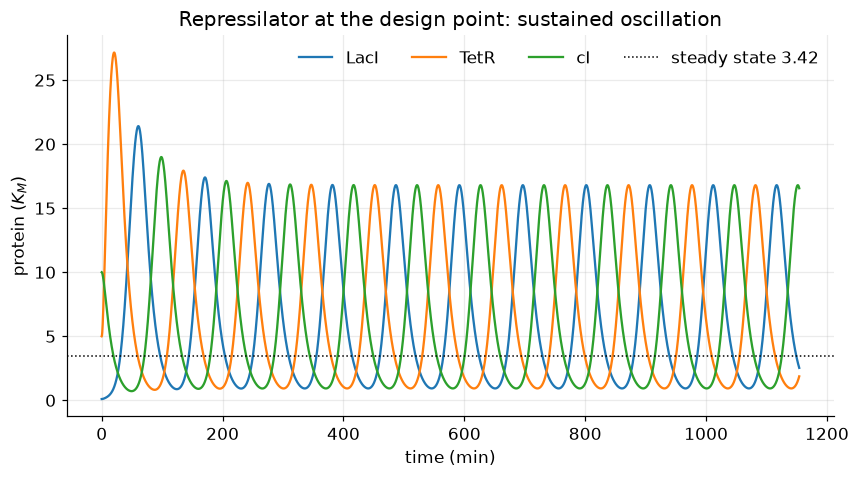

steady state p* = 3.423
peak-to-peak period = 105.0 min


In [2]:
initial_state = np.array([0.1, 5.0, 10.0, 0.1, 5.0, 10.0])
t_end = 400.0                      # 400 mRNA lifetimes ~ 1150 min

solution = solve_ivp(
    repressilator_rhs, [0.0, t_end], initial_state,
    args=(ALPHA, ALPHA_0, BETA, N_HILL),
    rtol=1e-8, atol=1e-10, dense_output=True, max_step=0.05,
)
time = np.linspace(0.0, t_end, 8000)
protein = solution.sol(time)[3:6]

p_star = steady_state_protein(ALPHA, ALPHA_0, N_HILL)

fig, axis = plt.subplots(figsize=(9, 4.5))
names = ["LacI", "TetR", "cI"]
for i in range(3):
    axis.plot(time * MRNA_LIFETIME_MIN, protein[i], lw=1.5, label=names[i])
axis.axhline(p_star, color="black", ls=":", lw=1.0, label=f"steady state {p_star:.2f}")
axis.set_xlabel("time (min)")
axis.set_ylabel("protein ($K_M$)")
axis.set_title("Repressilator at the design point: sustained oscillation")
axis.legend(ncol=4)
plt.show()

peaks, _ = find_peaks(protein[0])
peak_times = time[peaks]
peak_times = peak_times[peak_times > 200.0]
print("steady state p* =", round(p_star, 3))
print("peak-to-peak period =", round(np.mean(np.diff(peak_times)) * MRNA_LIFETIME_MIN, 1), "min")

## 2. It does not converge to the steady state

The steady state is unstable, so the trajectory cannot stay there. To show that the long-time
object is a **limit cycle** and not a slow transient, integrate from several initial conditions:
all of them must spiral onto the same closed curve. A second check is the period: once on the
cycle, every peak-to-peak interval is the same.

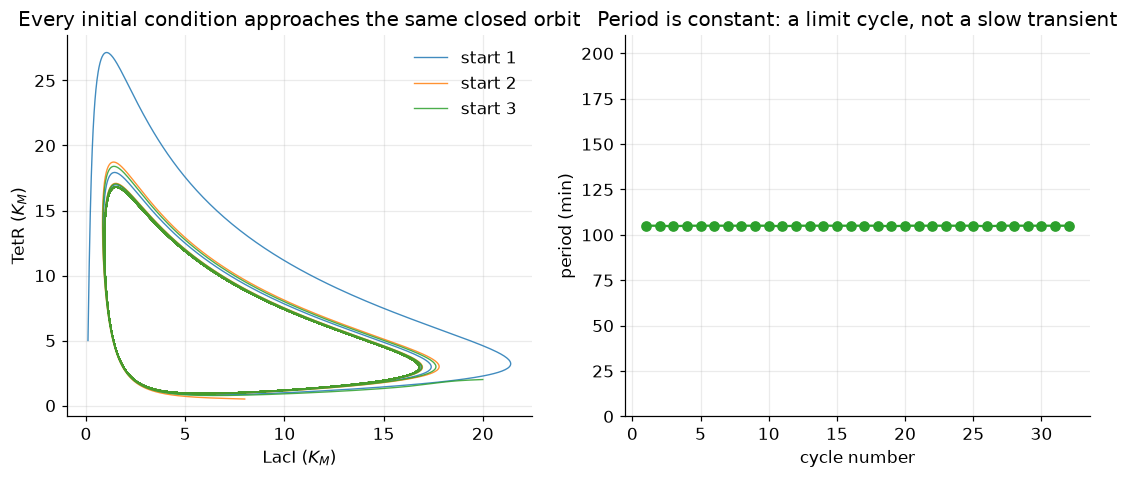

mean period = 105.0 min; spread = 0.1 min


In [3]:
initial_conditions = [
    np.array([0.1, 5.0, 10.0, 0.1, 5.0, 10.0]),
    np.array([8.0, 0.5, 3.0, 8.0, 0.5, 3.0]),
    np.array([1.0, 1.0, 1.0, 20.0, 2.0, 1.0]),
]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for k, initial in enumerate(initial_conditions):
    sol = solve_ivp(
        repressilator_rhs, [0.0, 1200.0], initial,
        args=(ALPHA, ALPHA_0, BETA, N_HILL),
        rtol=1e-8, atol=1e-10, dense_output=True, max_step=0.05,
    )
    tt = np.linspace(0.0, 1200.0, 12000)
    pp = sol.sol(tt)
    axes[0].plot(pp[3], pp[4], lw=0.9, alpha=0.85, label=f"start {k + 1}")

axes[0].set_xlabel("LacI ($K_M$)")
axes[0].set_ylabel("TetR ($K_M$)")
axes[0].set_title("Every initial condition approaches the same closed orbit")
axes[0].legend()

sol = solve_ivp(
    repressilator_rhs, [0.0, 1500.0], initial_conditions[0],
    args=(ALPHA, ALPHA_0, BETA, N_HILL),
    rtol=1e-8, atol=1e-10, dense_output=True, max_step=0.05,
)
tt = np.linspace(300.0, 1500.0, 12000)
lacI = sol.sol(tt)[3]
peaks, _ = find_peaks(lacI)
intervals = np.diff(tt[peaks]) * MRNA_LIFETIME_MIN

axes[1].plot(np.arange(1, len(intervals) + 1), intervals, "o-", color="tab:green")
axes[1].set_xlabel("cycle number")
axes[1].set_ylabel("period (min)")
axes[1].set_title("Period is constant: a limit cycle, not a slow transient")
axes[1].set_ylim(0.0, 2.0 * np.mean(intervals))
plt.show()

print("mean period =", round(np.mean(intervals), 1),
      "min; spread =", round(np.std(intervals), 2), "min")

## 3. Why it does not converge: linear stability and the Hopf condition

### Steady state

By symmetry all three species are equal, $m_i=p_i=p$, with

$$p=\frac{\alpha}{1+p^n}+\alpha_0 .$$

The right-hand side is strictly decreasing in $p$, so this equation has exactly one solution:
the symmetric steady state is unique.

### Linearization

Let

$$X\equiv\frac{\alpha n\,p^{\,n-1}}{(1+p^{\,n})^{2}}>0$$

be minus the slope of the repression function at the steady state. Ordering the variables as
$(m_1,m_2,m_3,p_1,p_2,p_3)$, the Jacobian is

$$J=\begin{pmatrix}-I & -X P\\ \beta I & -\beta I\end{pmatrix},$$

where $P$ maps $p_3\to m_1$, $p_1\to m_2$, $p_2\to m_3$. Because $P$ is a cyclic permutation its
eigenvalues are the cube roots of unity $\mu\in\{1,\omega,\omega^2\}$ with $\omega=e^{2\pi i/3}$,
so the characteristic equation splits into three quadratics

$$\lambda^2+(1+\beta)\lambda+\beta(1+X\mu)=0 .$$

### Hopf condition

For $\mu=1$ both roots have $\operatorname{Re}\lambda=-(1+\beta)/2<0$: this mode never destabilizes
the state.

Instability comes from $\mu=\omega,\omega^2$. Put $\lambda=i\nu$ and use
$\operatorname{Re}\omega=-\tfrac12$, $\operatorname{Im}\omega=\tfrac{\sqrt3}{2}$. The real and
imaginary parts of the quadratic give

$$\nu^2=\beta\left(1-\frac{X}{2}\right),
\qquad
\nu=\frac{\beta X\sqrt3}{2(1+\beta)} .$$

Eliminating $\nu$ gives the Hopf boundary

$$\boxed{\ \frac{(\beta+1)^2}{\beta}=\frac{3X^2}{4-2X}\ }$$

A complex pair crosses the imaginary axis — the Hopf condition — when the left side is smaller:

$$\frac{(\beta+1)^2}{\beta}<\frac{3X^2}{4-2X}.$$

This requires $X<2$. Since $\beta+2+\beta^{-1}$ has minimum $4$ at $\beta=1$, oscillation is
easiest when protein and mRNA lifetimes are comparable — exactly the role of the ssrA degradation
tag in the experiment.

At the design point $X=1.82$, so $3X^2/(4-2X)=27.5$ while $(\beta+1)^2/\beta=7.2$: the inequality
holds and the steady state is unstable. The eigenvalues are computed below.

### Rigor remark: from linear instability to a global oscillation

The linearization proves only that $p^*$ is a **hyperbolic saddle** at the design point: two
eigenvalues with positive real part and four with negative part. It does not by itself prove that
trajectories oscillate, and it does not say that *no* trajectory converges to $p^*$: the
four-dimensional stable manifold still attracts special initial conditions. The missing steps are
short because the circuit has a cyclic structure.

**Lemma 1 (boundedness).** For nonnegative initial data the box $[0,\alpha+\alpha_0]^6$ is forward
invariant, so every solution is bounded. Indeed $h(p)=\alpha/(1+p^n)+\alpha_0\in[0,\alpha+\alpha_0]$
and
$$\dot m_i=-m_i+h(p_{i-1})\quad\Rightarrow\quad
\dot m_i<0\ \text{if }m_i>\alpha+\alpha_0,\qquad \dot m_i>0\ \text{if }m_i<0,$$
while $\dot p_i=\beta(m_i-p_i)$ pushes $p_i$ toward the range of $m_i$.

**Lemma 2 (unique steady state).** At a steady state $m_i=p_i$, and going around the cycle
$p_i=g(p_{i-1})$ with $g(p)=\alpha/(1+p^n)+\alpha_0$. Hence $p_i=g^3(p_i)$ for every $i$. The map $g$
is continuous and strictly decreasing, so $g^3$ is strictly decreasing and has at most one fixed
point. Therefore the steady state is unique and symmetric — the point $p^*$.

**Structure.** Order the variables as $(m_1,p_1,m_2,p_2,m_3,p_3)$. Each equation has the form
$\dot x_i=f_i(x_i,x_{i-1})$ with $\partial f_i/\partial x_i<0$ and off-diagonal signs
$-,+,-,+,-,+$. The product of the off-diagonal signs is $(-1)^3=-1$: this is a **monotone cyclic
feedback system with negative feedback**.

**Theorem (Mallet–Paret & Smith, 1990).** For a bounded solution of a monotone cyclic feedback
system with negative feedback, the $\omega$-limit set is either a single equilibrium or a periodic
orbit.

**Conclusion.** Every solution is bounded (Lemma 1) and the only equilibrium is $p^*$ (Lemma 2).
Since $p^*$ is a hyperbolic saddle, its stable manifold has dimension $4<6$ and is a measure-zero
set; every other initial condition has an $\omega$-limit set that is not the equilibrium, hence by
the theorem a **periodic orbit**. Thus the circuit oscillates for almost every initial condition
and does not converge to the steady state. This is the precise meaning of "the repressilator
oscillates"; the figures below are the numerical confirmation.

*Reference: J. Mallet-Paret & H. L. Smith, J. Dyn. Diff. Eq. 2 (1990) 367–421.*

X = 1.820
            eigenvalue   real part
-0.6000+0.4516i     -0.6000
-0.6000-0.4516i     -0.6000
-1.2352+0.2481i     -1.2352
+0.0352-0.2481i      0.0352  <- unstable
-1.2352-0.2481i     -1.2352
+0.0352+0.2481i      0.0352  <- unstable

Hopf frequency nu = 0.263 per mRNA lifetime
linear period estimate = 69.0 min


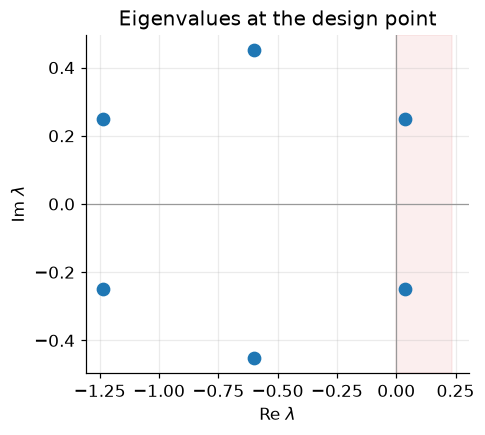

In [4]:
p_star = steady_state_protein(ALPHA, ALPHA_0, N_HILL)
X = repression_slope(ALPHA, ALPHA_0, N_HILL)
omega = np.exp(2j * np.pi / 3)

eigenvalues = []
for mu in [1.0, omega, np.conjugate(omega)]:
    for root in np.roots([1.0, 1.0 + BETA, BETA * (1.0 + X * mu)]):
        eigenvalues.append(root)
eigenvalues = np.array(eigenvalues)

print(f"X = {X:.3f}")
print(f"{'eigenvalue':>22}{'real part':>12}")
for value in eigenvalues:
    flag = "  <- unstable" if value.real > 0 else ""
    print(f"{value.real:+.4f}{value.imag:+.4f}i{value.real:>12.4f}{flag}")

nu = BETA * X * np.sqrt(3.0) / (2.0 * (1.0 + BETA))
print()
print("Hopf frequency nu =", round(nu, 3), "per mRNA lifetime")
print("linear period estimate =", round(2 * np.pi / nu * MRNA_LIFETIME_MIN, 1), "min")

fig, axis = plt.subplots(figsize=(4.5, 4.0))
axis.axhline(0, color="0.6", lw=0.8)
axis.axvline(0, color="0.6", lw=0.8)
axis.axvspan(0, eigenvalues.real.max() + 0.2, color="tab:red", alpha=0.08)
axis.plot(eigenvalues.real, eigenvalues.imag, "o", color="tab:blue", ms=8)
axis.set_xlabel(r"Re $\lambda$")
axis.set_ylabel(r"Im $\lambda$")
axis.set_title("Eigenvalues at the design point")
plt.show()

## 4. The phase diagram of the paper (Fig. 1b)

The Hopf condition is a boundary in the $(\alpha,\beta)$ plane. For each $\alpha$ we find $p$,
then $X$, then solve for the two $\beta$ values that make the inequality an equality:

$$R(\alpha)\equiv\frac{3X^2}{4-2X},\qquad
\beta_\pm=\frac{(R-2)\pm\sqrt{(R-2)^2-4}}{2}.$$

The unstable interval is $\beta_-<\beta<\beta_+$; since $\beta_-\beta_+=1$ the two branches are
reciprocals. The paper plots *protein lifetime / mRNA lifetime*, which is $1/\beta$ in the Box 1
notation. The function $(\beta+1)^2/\beta$ is invariant under $\beta\to1/\beta$, so this change of
variable leaves the boundary unchanged and we can plot $\beta_+$ directly. The lower branch
$\beta_-$ lies below $1$ and is outside the plotted range.

| curve | $n$ | leak $\alpha_0/\alpha$ | what changes |
|---|---|---|---|
| A (solid) | 2.1 | 0 | larger $n$: boundary turns vertical, no upper limit on $\beta$ |
| B (dashed) | 2 | 0 | baseline repressilator |
| C (dash-dot) | 2 | $10^{-3}$ | leak shrinks the region; at large $\alpha$ the leak dominates and the curve turns back down |

The shaded region below curve A is unstable. The design point $(43,5)$ lies inside it.

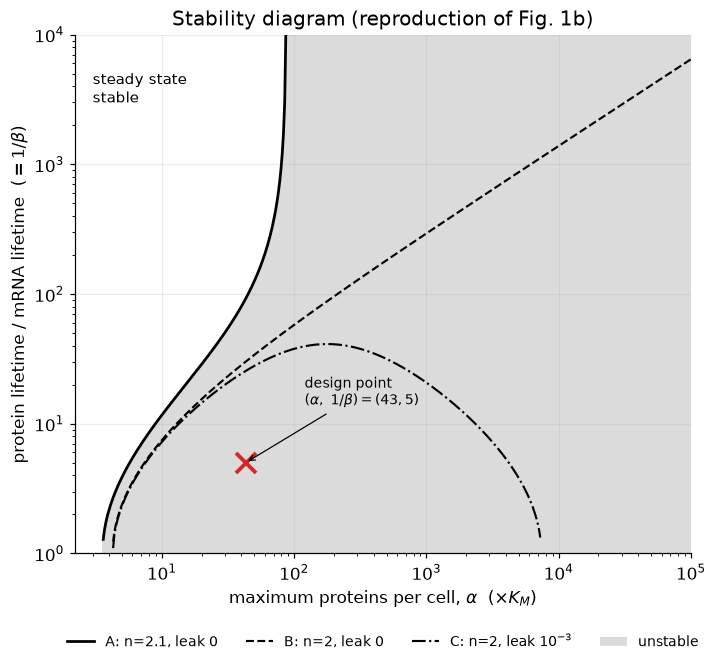

In [5]:
def hopf_upper_branch(alpha_values, n_hill, leak_ratio):
    upper = np.full(alpha_values.shape, np.nan)
    for k in range(len(alpha_values)):
        alpha = alpha_values[k]
        alpha0 = leak_ratio * alpha
        X = repression_slope(alpha, alpha0, n_hill)
        if X >= 2.0:                 # unstable for every beta
            upper[k] = np.inf
            continue
        R = 3.0 * X**2 / (4.0 - 2.0 * X)
        if R < 4.0:                  # stable for every beta
            continue
        upper[k] = ((R - 2.0) + np.sqrt((R - 2.0)**2 - 4.0)) / 2.0
    return upper


alpha_grid = np.logspace(np.log10(2.2), 5.0, 500)
curve_A = hopf_upper_branch(alpha_grid, 2.1, 0.0)
curve_B = hopf_upper_branch(alpha_grid, 2.0, 0.0)
curve_C = hopf_upper_branch(alpha_grid, 2.0, 1e-3)

alpha_star = brentq(lambda a: repression_slope(a, 0.0, 2.1) - 2.0, 10.0, 1000.0)

# unstable mask: below curve A, and every beta to the right of alpha_star
lifetime_axis = np.logspace(0.0, 4.0, 300)
alpha_mesh, lifetime_mesh = np.meshgrid(alpha_grid, lifetime_axis)
unstable = np.zeros(alpha_mesh.shape, dtype=int)
for k in range(len(alpha_grid)):
    boundary = curve_A[k]
    if np.isinf(boundary):
        unstable[:, k] = 1
    elif np.isfinite(boundary):
        unstable[:, k] = lifetime_mesh[:, k] < boundary

from matplotlib.patches import Patch

fig, axis = plt.subplots(figsize=(6.8, 6.2))
axis.contourf(alpha_mesh, lifetime_mesh, unstable,
              levels=[0.5, 1.5], colors=["0.86"], zorder=0)

line_A, = axis.plot(alpha_grid, curve_A, color="black", lw=1.8, label="A: n=2.1, leak 0")
line_B, = axis.plot(alpha_grid, curve_B, color="black", lw=1.4, ls="--", label="B: n=2, leak 0")
line_C, = axis.plot(alpha_grid, curve_C, color="black", lw=1.4, ls="-.", label="C: n=2, leak $10^{-3}$")
unstable_patch = Patch(facecolor="0.86", edgecolor="none", label="unstable")

axis.plot(ALPHA, 1.0 / BETA, "x", color="tab:red", ms=13, mew=2.5)
axis.annotate("design point\n$(\\alpha,\\ 1/\\beta)=(43,5)$", xy=(ALPHA, 5.0),
              xytext=(120, 14), fontsize=9,
              arrowprops=dict(arrowstyle="->", lw=0.8))

axis.set_xscale("log")
axis.set_yscale("log")
axis.set_xlim(2.2, 1e5)
axis.set_ylim(1.0, 1e4)
axis.set_xlabel(r"maximum proteins per cell, $\alpha$  $(\times K_M)$")
axis.set_ylabel(r"protein lifetime / mRNA lifetime  $(=1/\beta)$")
axis.set_title("Stability diagram (reproduction of Fig. 1b)")
axis.text(3.0, 3e3, "steady state\nstable", fontsize=10)
axis.legend(handles=[line_A, line_B, line_C, unstable_patch],
            loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=4, fontsize=9)
fig.tight_layout()
plt.show()

## 5. Which circuits converge to a steady state

The repressilator oscillates because of three ingredients: **negative feedback**, a loop that is
effectively **long enough**, and **cooperative** repression. Remove any one and the state becomes
stable.

**A single self-repressing gene.** For one gene the Jacobian has only the $\mu=1$ mode,

$$\lambda^2+(1+\beta)\lambda+\beta(1+X)=0,\qquad X>0,$$

so both roots have negative real part for every parameter value. A one-gene negative feedback is a
two-dimensional system with no delay; it always converges. Oscillation would need an explicit
delay or a third component.

**An even number of repressors.** Two repressors that inhibit each other make an overall
*positive* feedback. The $\mu=-1$ mode gives

$$\lambda^2+(1+\beta)\lambda+\beta(1-X)=0,$$

whose roots cross through zero at $X=1$ — a real eigenvalue, not a complex pair. The state does
not start to oscillate; it becomes bistable, and the system converges to one of two stable
high–low states. Rings of four (or any even number) are sign-equivalent to a cooperative system
and generically converge to a fixed point.

**An odd number of repressors.** Three (or any odd number $\ge 3$) give an overall negative
feedback, and the complex pair can cross the imaginary axis: this is the Hopf route to a limit
cycle.

**Positive feedback.** A toggle switch (mutual activation, or mutual repression seen in the right
variables) has stable steady states and hysteresis — it also converges, just to one of several
states.

So oscillation versus convergence is decided by the **sign of the feedback loop** together with
**cooperativity and timescales**, not by the presence of feedback alone.

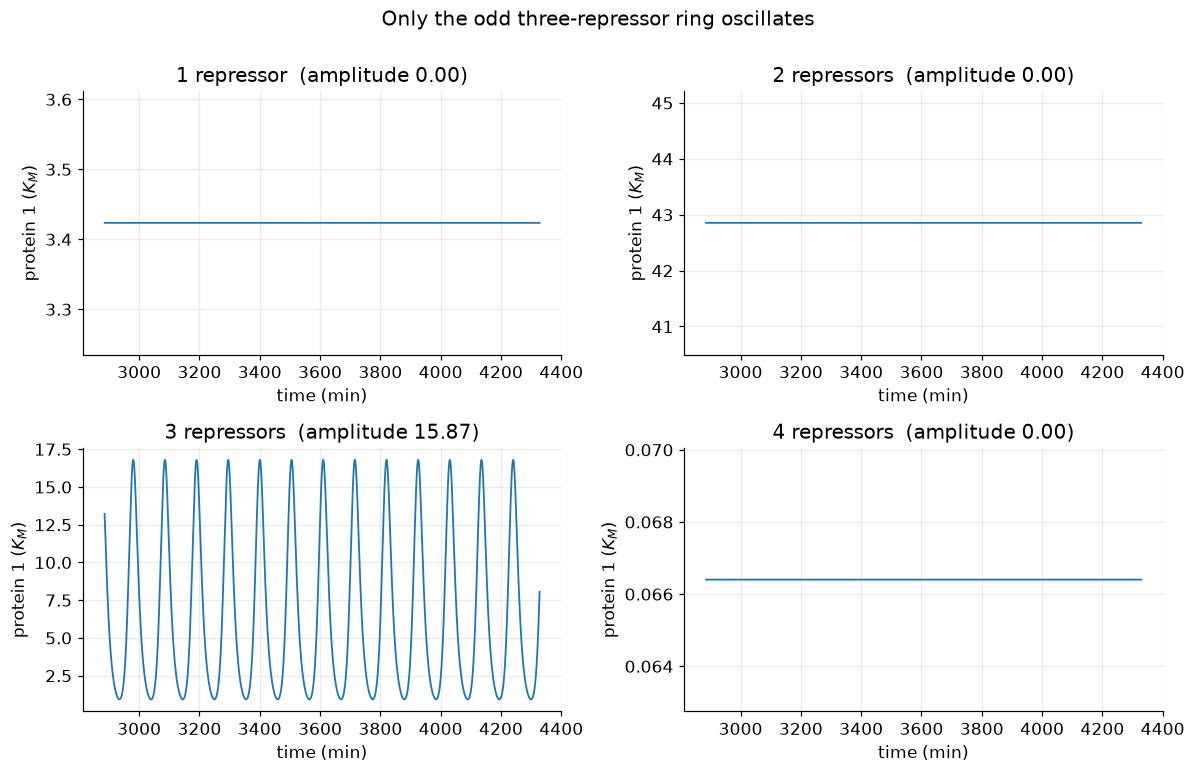

N=2 start  LacI high: final p = (42.85, 0.07)


N=2 start  TetR high: final p = (0.07, 42.85)


In [6]:
def ring_rhs(t, state, n_species, alpha, alpha0, beta, n_hill):
    mrna = state[:n_species]
    protein = state[n_species:]
    repressor_index = [(i - 1) % n_species for i in range(n_species)]
    upstream = protein[repressor_index]
    dmrna = -mrna + alpha / (1.0 + upstream**n_hill) + alpha0
    dprotein = beta * (mrna - protein)
    return np.concatenate([dmrna, dprotein])


def simulate_ring(n_species, alpha, alpha0, beta, n_hill, t_end, initial_state):
    return solve_ivp(ring_rhs, [0.0, t_end], initial_state,
                     args=(n_species, alpha, alpha0, beta, n_hill),
                     rtol=1e-8, atol=1e-9, dense_output=True, max_step=0.1)


rng = np.random.default_rng(7)
p_star = steady_state_protein(ALPHA, ALPHA_0, N_HILL)
t_end = 1500.0
time = np.linspace(1000.0, t_end, 4000)

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for axis, n_species in zip(axes.ravel(), [1, 2, 3, 4]):
    symmetric = np.full(2 * n_species, p_star)
    initial_state = np.abs(symmetric * (1.0 + 0.1 * rng.standard_normal(2 * n_species)))

    solution = simulate_ring(n_species, ALPHA, ALPHA_0, BETA, N_HILL, t_end, initial_state)
    trace = solution.sol(time)[n_species]
    amplitude = trace.max() - trace.min()

    axis.plot(time * MRNA_LIFETIME_MIN, trace, lw=1.2)
    axis.set_title(f"{n_species} repressor{'s' if n_species > 1 else ''}  "
                   f"(amplitude {amplitude:.2f})")
    axis.set_xlabel("time (min)")
    axis.set_ylabel("protein 1 ($K_M$)")

fig.suptitle("Only the odd three-repressor ring oscillates", y=1.00)
plt.tight_layout()
plt.show()

# the two-repressor ring is bistable: opposite starts give mirror-image states
for first_high in [True, False]:
    if first_high:
        start = np.array([40.0, 0.05, 40.0, 0.05])
    else:
        start = np.array([0.05, 40.0, 0.05, 40.0])
    sol = simulate_ring(2, ALPHA, ALPHA_0, BETA, N_HILL, 2000.0, start)
    final = sol.y[:, -1]
    label = "LacI high" if first_high else "TetR high"
    print(f"N=2 start {label:>10}: final p = ({final[2]:.2f}, {final[3]:.2f})")

## Conclusion

- At the paper's parameters the steady state is **unique and hyperbolic**, with a complex pair of
  real part $+0.035$ (a saddle with a 4-dimensional stable manifold). Generic trajectories do not
  converge to it; the global argument in §3 and the simulations show they approach a periodic
  orbit.
- Trajectories stay bounded and every initial condition approaches the **same closed orbit** with
  a constant period of about **105 min**. The Hopf condition locates this transition in the
  $(\alpha,\beta)$ plane and reproduces Fig. 1b.
- Oscillation needs an **odd negative-feedback loop** of at least three repressors,
  **cooperativity** ($n>1$) and **comparable lifetimes** ($\beta\sim1$, $X<2$). A one-gene loop and
  even rings have stable steady states; the two-repressor ring is bistable. That is why the
  repressilator was a non-trivial design, and why the ssrA degradation tags mattered.